In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [4]:
df = pd.read_csv("C:/Users/CeX-Laguna/OneDrive/Escritorio/amz_uk_price_prediction_dataset.csv")

In [7]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [9]:
frequency_table = df['category'].value_counts()

proportion_table = df['category'].value_counts(normalize=True)

frequency_table, proportion_table

(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
                                            ...  
 Motorbike Chassis                            107
 Alexa Built-In Devices                       107
 Plugs                                        107
 Smart Home Security & Lighting               104
 Smart Speakers                                54
 Name: count, Length: 296, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
                                             ...   
 Motorbike Chassis                         0.000044
 Alexa Built-In Devices  

Las 5 categorías más listadas son: Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body y Birthday Gifts.

C:\Users\CeX-Laguna\AppData\Local\Temp\ipykernel_16652\1730447042.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5.values, y=top_5.index, palette="Set3")


<Axes: ylabel='category'>

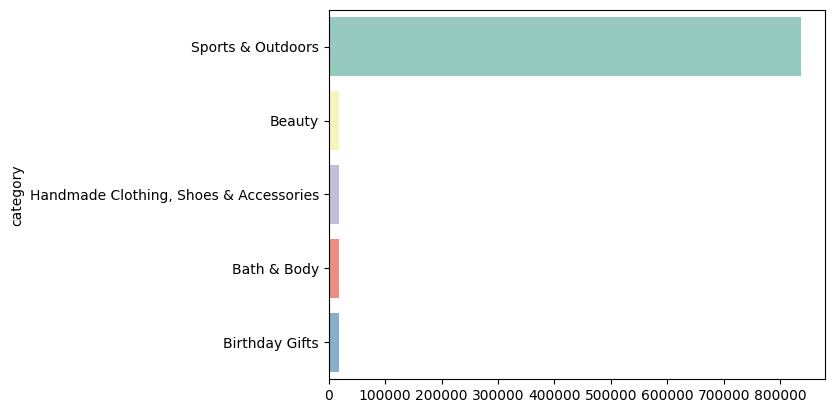

In [36]:
top_5 = frequency_table.head(5)

sns.barplot(x=top_5.values, y=top_5.index, palette="Set3")


Para un subconjunto de las categorías principales, visualiza sus proporciones mediante un gráfico circular. 

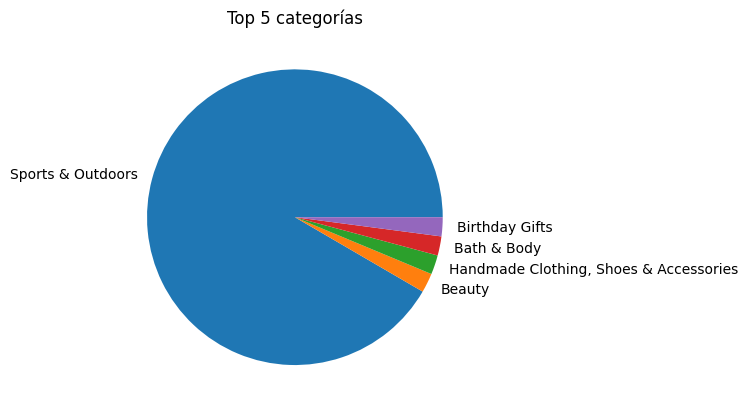

In [ ]:
# Tomar los 5 valores principales
top_5 = frequency_table.sort_values(ascending=False).head(5)

# Pie chart
plt.pie(top_5.values, labels=top_5.index)
plt.title("Top 5 categorías")
plt.show()


Profundizando en la fijación de precios de los productos
Pregunta comercial : ¿Cómo se fijan los precios de los productos en Amazon Reino Unido? ¿Existen precios o rangos específicos que sean más comunes?

1. Medidas de centralidad :

Calcula la media, la mediana y la moda para los priceproductos.
¿Cuál es el precio promedio de los productos listados? ¿Cómo se compara esto con el precio más común (moda)?

In [20]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

In [17]:
mean_price

np.float64(89.24380943923663)

In [18]:
median_price 

np.float64(19.09)

In [21]:
mode_price

np.float64(9.99)

En comparación con la moda, los precios de la media y de la mediana, son muy elevados.

2. Medidas de dispersión :

Determine la varianza, la desviación estándar, el rango y el rango intercuartílico del producto price.

In [22]:
std_price = df['price'].std()
var_price = df['price'].var()
min_price = df['price'].min()
max_price = df['price'].max()

In [23]:
std_price

np.float64(345.60886175349884)

In [24]:
var_price

np.float64(119445.48532254907)

In [29]:
rango = max_price - min_price

In [30]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

In [31]:
print("Primer cuartil (Q1):", Q1)
print("Tercer cuartil (Q3):", Q3)
print("Rango intercuartílico (IQR):", IQR)


Primer cuartil (Q1): 9.99
Tercer cuartil (Q3): 45.99
Rango intercuartílico (IQR): 36.0


¿Qué tan variados son los precios de los productos? ¿Existen indicadores de una diferencia significativa en los precios?

- La diferencia entre la media, la mediana y la moda indica una distribución hacia la derecha, es decir, la mayoría de los productos tienen precios bajos, pero existen algunos productos muy caros que elevan la media. 
- La desviación estándar y varianza son muy altas, lo que confirma que los precios están muy dispersos y alejados del promedio.

- En conjunto, estos indicadores muestran que existen diferencias de precio significativas entre los productos y la presencia de valores altos extremos probablemente está afectando los valores medios.

3. VISUALIZACIONES

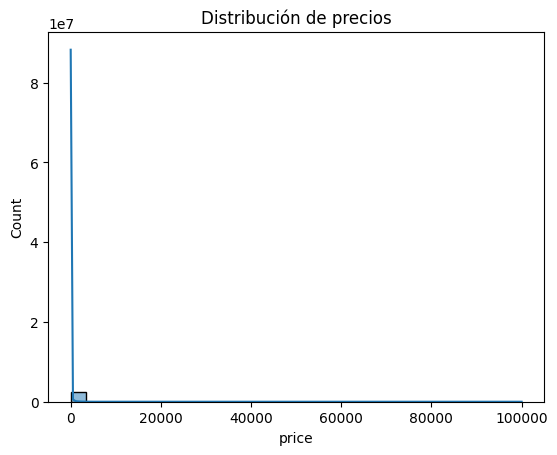

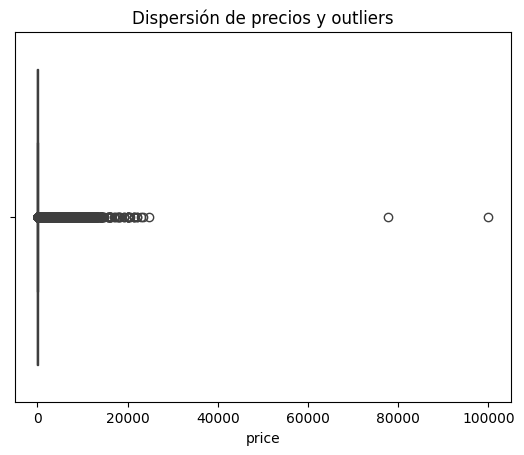

In [35]:
# Histograma
sns.histplot(df['price'], kde=True, bins=30)
plt.title('Distribución de precios')
plt.show()

# Boxplot
sns.boxplot(x=df['price'])
plt.title('Dispersión de precios y outliers')
plt.show()


3. Media, mediana y moda del rating.

In [37]:
mean_stars = df['stars'].mean()
median_stars = df['stars'].mean()
mode_stars = df['stars'].mean()

print('Media: ', mean_stars)
print('Mediana: ', mean_stars)
print('Moda: ', mean_stars)


Media:  2.152836472966065
Mediana:  2.152836472966065
Moda:  2.152836472966065


In [48]:
print('Media: ', mean_stars)

Media:  2.152836472966065


In [49]:
print('Mediana: ', mean_stars)

Mediana:  2.152836472966065


In [50]:
print('Moda: ', mean_stars)

Moda:  2.152836472966065


¿Cómo suelen valorar los clientes los productos? ¿Existe alguna tendencia común?

### Medidas de dispersión :

Determine la varianza, la desviación estándar y el rango intercuartílico del producto rating.
¿Las valoraciones son coherentes o existe una gran variación en las opiniones de los clientes?

In [38]:
std_stars = df['stars'].std()
var_stars = df['stars'].var()
min_stars = df['stars'].min()
max_stars = df['stars'].max()

rango = max_stars - min_stars

In [51]:
rango = max_stars - min_stars

In [53]:
Q1 = df['stars'].quantile(0.25)
Q3 = df['stars'].quantile(0.75)
IQR = Q3 - Q1
print("Rango intercuartílico (IQR):", IQR)

Rango intercuartílico (IQR): 4.4


Esto da como resultado que hay una gran variedad de opiniones de los clientes.

### CALCULA SKEWNESS Y KURTOSIS
Forma de la distribución :

Calcule la asimetría y la curtosis de la ratingcolumna.
¿Las calificaciones se distribuyen normalmente o tienden hacia valores más altos o más bajos?

In [46]:
skewness_stars = df['stars'].skew()
kurtosis_stars = df['stars'].kurtosis()



In [44]:
skewness_stars


np.float64(0.08120735761080985)

Esto indica que las valoraciones no están inclinadas hacia notas bajas ni altas; se distribuyen de manera equilibrada alrededor de la media.

In [47]:
kurtosis_stars

np.float64(-1.9260061280432985)

Los clientes tienden a dar opiniones más variadas, pero sin valores extremos muy altos o muy bajos.

### VISUALIZACIONES

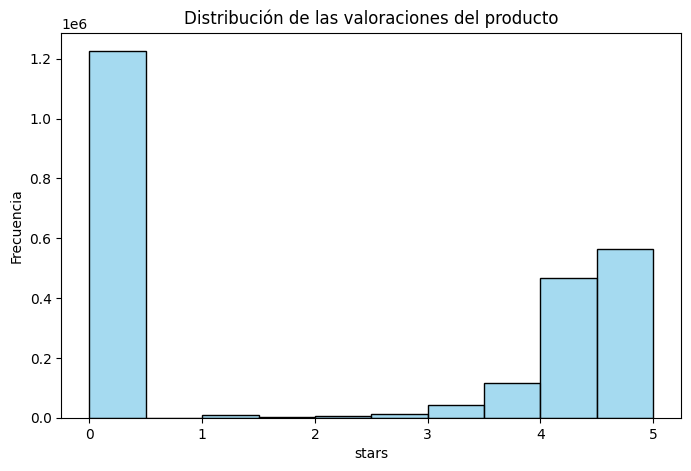

In [56]:
plt.figure(figsize=(8,5))
sns.histplot(df['stars'], bins=10, kde=False, color='skyblue')
plt.title("Distribución de las valoraciones del producto")
plt.xlabel("stars")
plt.ylabel("Frecuencia")
plt.xticks(range(int(df['stars'].min()), int(df['stars'].max())+1))  # para que se vea cada rating
plt.show()

Con está gráfica se demuestra que la gente no valorá, pero si lo hace son con buenas puntuaciones.